# Small-town America, after the mill

Bowling Alone is a book about civic life. Underneath it is a geographic fact that is hard to see in a single official urban-share chart: work and people used to sit together in mill towns, then the work left, and the meaning of "rural" moved while we were looking at percentages.

A place of 30,000 people in the 1770s was a city. Philadelphia was the second city of the United States in 1790, with 28,522 residents. A place of 30,000 today is a small city on a good day, and often a suburb. The Census line for "urban" was 2,500 people for most of American history, then 5,000 in 2020. Those thresholds did not travel with the country.

This notebook does two things.

**What counted as a city.** Rank sizes of the largest urban places from every census, 1790–2023, set against Philadelphia in 1790 and against the official urban population counted as people, not as a percent.

**Where the manufacturing pile went.** County manufacturing jobs and county population, 1969–2022, split by a *fixed* 1974 metro/nonmetro line so that urbanization is not just OMB redrawing the map. The question is whether mill-town jobs moved into cities, vanished, or were redefined away when counties were annexed into metro areas. A second split uses the contemporaneous rural-urban codes, so reclassification is visible as its own path.

The two figures are `philadelphia_shadow.png` and `taken_from_the_pile.png`.


## How to run

Run this notebook from the `small-town-america` directory, so `../data` is the repo-root data folder. The first run downloads Census, USDA ERS, BEA, and FRED files into `../data/small-town-america/`. Later runs reuse them.

```bash
cd small-town-america
uv venv --python 3.13 .venv
uv pip install -r requirements.txt
```

Open the notebook with that environment and run all cells. The figures are written next to the notebook.


## Setup


In [1]:
%matplotlib inline

from __future__ import annotations

import io
import re
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore", message=".*xlrd engine is deprecated.*")

HERE = Path.cwd()
if not (HERE / "urbanization.ipynb").exists():
    raise FileNotFoundError("Run this notebook from the small-town-america directory.")
DATA = (HERE / "../data/small-town-america").resolve()
DATA.mkdir(parents=True, exist_ok=True)

USER_AGENT = "small-town-america-notebook/1.0 (historical urbanization and manufacturing)"

INK = "#1c1915"
PAPER = "#f3eee4"
GOLD = "#c4a35a"
MILL = "#a3533c"
STEEL = "#2c4a5e"
GONE = "#ddd4c6"
RURAL = "#b7a48a"
RULE = "#cfc6b8"

PHILADELPHIA_1790 = 28_522
NYC_1790 = 33_131
URBAN_OLD = 2_500
URBAN_2020 = 5_000

plt.rcParams.update(
    {
        "figure.facecolor": PAPER,
        "axes.facecolor": PAPER,
        "savefig.facecolor": PAPER,
        "text.color": INK,
        "axes.labelcolor": INK,
        "xtick.color": INK,
        "ytick.color": INK,
        "axes.edgecolor": RULE,
        "axes.unicode_minus": False,
        "font.size": 11,
        "axes.titlesize": 13,
        "figure.titlesize": 16,
    }
)


def download(url: str, dest: Path) -> Path:
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    request = urllib.request.Request(url, headers={"User-Agent": USER_AGENT})
    with urllib.request.urlopen(request, timeout=180) as response:
        dest.write_bytes(response.read())
    return dest


def millions(x, _pos=None):
    if abs(x) >= 1_000_000:
        return f"{x / 1_000_000:.0f}M"
    if abs(x) >= 1_000:
        return f"{x / 1_000:.0f}k"
    return f"{x:.0f}"


## Data

Four families of files, all public.

**Largest urban places, 1790–1990.** Census Population Division Working Paper No. 27 (Gibson 1998). Table 24 is the size of the 1st through 100th place at each census. Tables 2–22 are the named places, used for Philadelphia and a few mill-town traces. Through 1940 these are incorporated places. After 1950 a few unincorporated places enter.

**Incorporated place estimates, 2000–2023.** Census Population Estimates Program. SUMLEV 162 is a place (city, town, village). These are not identical to Gibson's "urban place" after 1950, so the rank series has a documented seam at 2000.

**National urban and rural counts, 1790–2020.** Census CPH-2 Table 4 for 1790–1990 (current urban definition from 1950), Census 2000 and 2010 SF1 table P2, and the 2020 urban-area facts. The 2020 list of urban areas is used to ask how many of today's urban areas would have been smaller than colonial Philadelphia.

**Manufacturing jobs and people, 1969–2022.** BEA CAEMP25S (SIC manufacturing, line 400, 1969–2000) and CAEMP25N (NAICS manufacturing, line 500, 2001–2022) at the county level. BEA CAINC1 line 2 is county population. USDA ERS Rural-Urban Continuum Codes from 1974, 1993, 2003, 2013, and 2023 classify those counties. FRED `MANEMP` is the national wage-and-salary manufacturing series, a check on the BEA job counts, which include proprietors.

The 1974 codes are held fixed in the main split: a county that was nonmetro in 1974 stays on the mill-town side of the pile even if it was later pulled into a metro area. Contemporaneous codes are the comparison that lets the definition of rural move.


In [2]:
GIBSON = "https://www2.census.gov/library/working-papers/1998/demo/pop-twps0027"
ERS = "https://www.ers.usda.gov/sites/default/files/_laserfiche/DataFiles/53251"
CENSUS2 = "https://www2.census.gov"

FILES = {
    "tab24.txt": f"{GIBSON}/tab24.txt",
    "tab23.txt": f"{GIBSON}/tab23.txt",
    "CAEMP25S.zip": "https://apps.bea.gov/regional/zip/CAEMP25S.zip",
    "CAEMP25N.zip": "https://apps.bea.gov/regional/zip/CAEMP25N.zip",
    "CAINC1.zip": "https://apps.bea.gov/regional/zip/CAINC1.zip",
    "rucc1974.xls": f"{ERS}/ruralurbancodes1974.xls",
    "rucc2003.xls": f"{ERS}/ruralurbancodes2003.xls",
    "rucc2013.xls": f"{ERS}/ruralurbancodes2013.xls",
    "rucc2023.csv": f"{ERS}/Ruralurbancontinuumcodes2023.csv",
    "sub_est00int.csv": f"{CENSUS2}/programs-surveys/popest/datasets/2000-2010/intercensal/cities/sub-est00int.csv",
    "SUB-EST2020_ALL.csv": f"{CENSUS2}/programs-surveys/popest/datasets/2010-2020/cities/SUB-EST2020_ALL.csv",
    "sub-est2023.csv": f"{CENSUS2}/programs-surveys/popest/datasets/2020-2023/cities/totals/sub-est2023.csv",
    "ua_2020.xlsx": f"{CENSUS2}/geo/docs/reference/ua/2020_Census_ua_list_all.xlsx",
    "urban_rural_2010_2020.xlsx": f"{CENSUS2}/geo/docs/reference/ua/State_Urban_Rural_Pop_2020_2010.xlsx",
    "manemp.csv": "https://fred.stlouisfed.org/graph/fredgraph.csv?id=MANEMP",
}

for i in range(2, 23):
    FILES[f"tab{i:02d}.txt"] = f"{GIBSON}/tab{i:02d}.txt"

for name, url in FILES.items():
    dest = DATA / name
    download(url, dest)
    print(f"{dest.name:28s} {dest.stat().st_size:10,d} bytes")


tab24.txt                         5,453 bytes
tab23.txt                        23,149 bytes
CAEMP25S.zip                 11,776,810 bytes
CAEMP25N.zip                 11,050,299 bytes
CAINC1.zip                    3,467,441 bytes
rucc1974.xls                    373,760 bytes
rucc2003.xls                    446,976 bytes
rucc2013.xls                    420,352 bytes
rucc2023.csv                    629,322 bytes
sub_est00int.csv              9,015,719 bytes
SUB-EST2020_ALL.csv          10,185,581 bytes
sub-est2023.csv               6,714,548 bytes
ua_2020.xlsx                    298,361 bytes
urban_rural_2010_2020.xlsx       37,713 bytes
manemp.csv                       17,906 bytes
tab02.txt                         1,903 bytes
tab03.txt                         2,465 bytes
tab04.txt                         3,272 bytes
tab05.txt                         4,071 bytes
tab06.txt                         5,812 bytes
tab07.txt                         6,391 bytes
tab08.txt                         

## Largest places, 1790–2023

Gibson table 24 is already a rank-size series. The named year tables are parsed for Philadelphia and for mill towns that appear often enough to leave a trace. Place estimates after 2000 extend the ranks, with a seam: they are incorporated places, not the slightly broader "urban place" of the later Gibson tables.


In [3]:
PLACE_RE = re.compile(
    r"(\d+)t?\s+(.+?,\s*[A-Z]{2})\s*\*?\s*\.{2,}\s+([\d,]+)"
)


def parse_gibson_places(path: Path, year: int) -> pd.DataFrame:
    text = path.read_text(encoding="latin-1")
    rows = []
    for match in PLACE_RE.finditer(text):
        rows.append(
            {
                "year": year,
                "rank": int(match.group(1)),
                "place": re.sub(r"\s+", " ", match.group(2)).strip(" *"),
                "population": int(match.group(3).replace(",", "")),
            }
        )
    return pd.DataFrame(rows)


def parse_gibson_ranks(path: Path) -> pd.DataFrame:
    text = path.read_text(encoding="latin-1")
    ranks_a = (1, 2, 3, 4, 5, 10, 15, 20, 25)
    ranks_b = (30, 40, 50, 60, 70, 75, 80, 90, 100)
    blocks = {ranks_a: [], ranks_b: []}
    current = None
    for line in text.splitlines():
        stripped = line.strip()
        if stripped.startswith("Year") and "1st" in stripped:
            current = ranks_a
            continue
        if stripped.startswith("Year") and "30th" in stripped:
            current = ranks_b
            continue
        if current is None or not re.match(r"^\d{4}", stripped):
            continue
        year = int(stripped[:4])
        tokens = re.split(r"\s+", stripped[4:].lstrip(". ").replace(",", ""))
        if len(tokens) != len(current):
            raise ValueError(f"rank row {year} has {tokens!r}")
        for rank, token in zip(current, tokens):
            if token in {"(X)", "X"}:
                continue
            blocks[current].append({"year": year, "rank": rank, "population": int(token)})
    return pd.DataFrame(blocks[ranks_a] + blocks[ranks_b])


def parse_tab23(path: Path) -> pd.DataFrame:
    text = path.read_text(encoding="latin-1")
    row_re = re.compile(
        r"^([A-Za-z].+?)\s*\*{0,1}\.{2,}\s+([\d,]+)\s+([\d.]+)\s+(\d{4})\s+([\d,]+)\s*$"
    )
    rows = []
    state = None
    for line in text.splitlines():
        if re.fullmatch(r"[A-Z][A-Z ]+", line.strip()) and "POPULATION" not in line:
            state = line.strip().title()
            continue
        match = row_re.match(line.strip())
        if not match or state is None:
            continue
        rows.append(
            {
                "state": state,
                "place": re.sub(r"\s+", " ", match.group(1)).strip(" *"),
                "pop_1990": int(match.group(2).replace(",", "")),
                "pct_of_max": float(match.group(3)),
                "peak_year": int(match.group(4)),
                "peak_pop": int(match.group(5).replace(",", "")),
            }
        )
    return pd.DataFrame(rows)


place_tables = []
for year in range(1790, 2000, 10):
    table_no = 2 + (year - 1790) // 10
    parsed = parse_gibson_places(DATA / f"tab{table_no:02d}.txt", year)
    if parsed.empty:
        raise ValueError(f"no places parsed for {year}")
    place_tables.append(parsed)

gibson_places = pd.concat(place_tables, ignore_index=True)
gibson_ranks = parse_gibson_ranks(DATA / "tab24.txt")
ever_top = parse_tab23(DATA / "tab23.txt")

print(f"Gibson named place-years: {len(gibson_places):,}")
print(f"Gibson rank points:       {len(gibson_ranks):,}")
print(f"Places ever in the top 100, with a complete peak row: {len(ever_top):,}")
print(gibson_places.groupby("year").size().rename("n_places").head())
print("1790 Philadelphia in Gibson:")
print(
    gibson_places[
        (gibson_places["year"] == 1790)
        & gibson_places["place"].str.contains("Philadelphia", case=False)
    ]
)


Gibson named place-years: 1,828
Gibson rank points:       347
Places ever in the top 100, with a complete peak row: 243
year
1790    24
1800    33
1810    46
1820    61
1830    90
Name: n_places, dtype: int64
1790 Philadelphia in Gibson:
   year  rank                  place  population
1  1790     2  Philadelphia city, PA       28522


In [4]:
def incorporated_places(path: Path, pop_col: str, year: int) -> pd.DataFrame:
    df = pd.read_csv(path, dtype=str, encoding="latin-1")
    df.columns = [c.strip() for c in df.columns]
    df = df[df["SUMLEV"].astype(str).str.zfill(3) == "162"].copy()
    df = df[~df["STATE"].astype(str).str.zfill(2).isin(["72", "78", "66", "69", "60"])]
    df["population"] = pd.to_numeric(df[pop_col], errors="coerce")
    df = df.dropna(subset=["population"])
    df["year"] = year
    df["place"] = df["NAME"].str.strip() + ", " + df["STNAME"].str.strip()
    df["rank"] = df.groupby("year")["population"].rank(ascending=False, method="min").astype(int)
    return df[["year", "rank", "place", "population"]]


places_2000 = incorporated_places(DATA / "sub_est00int.csv", "ESTIMATESBASE2000", 2000)
places_2010 = incorporated_places(DATA / "sub_est00int.csv", "CENSUS2010POP", 2010)
places_2020 = incorporated_places(DATA / "SUB-EST2020_ALL.csv", "POPESTIMATE2020", 2020)
places_2023 = incorporated_places(DATA / "sub-est2023.csv", "POPESTIMATE2023", 2023)
modern_places = pd.concat(
    [places_2000, places_2010, places_2020, places_2023], ignore_index=True
)


def rank_slice(places: pd.DataFrame, ranks=(1, 2, 5, 10, 25, 50, 100)) -> pd.DataFrame:
    keep = places[places["rank"].isin(ranks)].copy()
    keep["population"] = keep["population"].astype(int)
    return keep[["year", "rank", "place", "population"]]


modern_ranks = rank_slice(modern_places)
rank_long = pd.concat(
    [gibson_ranks.assign(source="gibson"), modern_ranks.assign(source="pep")[["year", "rank", "population", "source"]]],
    ignore_index=True,
)

def city_series(name_re: str) -> pd.DataFrame:
    hist = gibson_places[gibson_places["place"].str.contains(name_re, case=False, regex=True)].copy()
    modern = modern_places[modern_places["place"].str.contains(name_re, case=False, regex=True)].copy()
    out = pd.concat([hist, modern], ignore_index=True)
    # One row per year: take the largest match, so "Philadelphia city" beats a township.
    return out.sort_values("population", ascending=False).groupby("year", as_index=False).first()


philadelphia = city_series(r"^Philadelphia city,")
new_york = city_series(r"^New York city,")
lowell = city_series(r"^Lowell city,")
youngstown = city_series(r"^Youngstown city,")
flint = city_series(r"^Flint city,")

print("Rank of the 100th place:")
print(
    rank_long[rank_long["rank"] == 100]
    .sort_values("year")[["year", "population", "source"]]
    .to_string(index=False)
)
print("\nPhiladelphia:")
print(philadelphia[["year", "rank", "population", "place"]].to_string(index=False))


Rank of the 100th place:
 year  population source
 1840        4226 gibson
 1850        7250 gibson
 1860        9552 gibson
 1870       14930 gibson
 1880       19743 gibson
 1890       30801 gibson
 1900       38307 gibson
 1910       53684 gibson
 1920       70983 gibson
 1930       85864 gibson
 1940       88039 gibson
 1950      106756 gibson
 1960      119574 gibson
 1970      138764 gibson
 1980      156804 gibson
 1990      170936 gibson
 2000      194943    pep
 2010      208453    pep
 2020      219945    pep
 2023      225564    pep

Philadelphia:
 year  rank  population                           place
 1790     2       28522           Philadelphia city, PA
 1800     2       41220           Philadelphia city, PA
 1810     2       53722           Philadelphia city, PA
 1820     2       63802           Philadelphia city, PA
 1830     3       80462           Philadelphia city, PA
 1840     4       93665           Philadelphia city, PA
 1850     4      121376           Philadelp

## Official urban and rural counts

Percent urban is a ratio. The numerator and the denominator both move, and the rule that fills the numerator changes. The table below uses the Census Bureau's published national counts: CPH-2 Table 4 through 1990, then P2 in 2000 and 2010, then the 2020 urban-area facts. Rural here is the residual — everyone not in urban territory — so it includes the open country and also the small places that the current threshold left out.


In [5]:
# Transcribed from Census CPH-2 Table 4 (1790-1990, current urban definition
# from 1950), Census 2000 and 2010 SF1 P2, and Census 2020 urban-area facts.
# 1960 rural uses the post-publication correction (54,054,425).
URBAN_RURAL = pd.DataFrame(
    [
        (1790, 3_929_214, 201_655, "places of 2,500+"),
        (1800, 5_308_483, 322_371, "places of 2,500+"),
        (1810, 7_239_881, 525_459, "places of 2,500+"),
        (1820, 9_638_453, 693_255, "places of 2,500+"),
        (1830, 12_860_702, 1_127_247, "places of 2,500+"),
        (1840, 17_069_453, 1_845_055, "places of 2,500+"),
        (1850, 23_191_876, 3_574_496, "places of 2,500+"),
        (1860, 31_443_321, 6_216_518, "places of 2,500+"),
        (1870, 38_558_371, 9_902_361, "places of 2,500+"),
        (1880, 50_189_209, 14_129_735, "places of 2,500+"),
        (1890, 62_979_766, 22_106_265, "places of 2,500+"),
        (1900, 76_212_168, 30_214_832, "places of 2,500+"),
        (1910, 92_228_496, 42_064_001, "places of 2,500+"),
        (1920, 106_021_537, 54_253_282, "places of 2,500+"),
        (1930, 123_202_624, 69_160_599, "places of 2,500+"),
        (1940, 132_164_569, 74_705_338, "places of 2,500+"),
        (1950, 151_325_798, 96_846_817, "urbanized areas + places of 2,500+"),
        (1960, 179_323_175, 125_268_750, "urbanized areas + places of 2,500+"),
        (1970, 203_302_031, 149_646_617, "urbanized areas + places of 2,500+"),
        (1980, 226_542_199, 167_050_992, "urbanized areas + places of 2,500+"),
        (1990, 248_709_873, 187_053_487, "urbanized areas + places of 2,500+"),
        (2000, 281_421_906, 222_360_539, "urbanized areas + urban clusters"),
        (2010, 308_745_538, 249_253_271, "urbanized areas + urban clusters"),
        (2020, 331_449_281, 265_149_027, "urban areas, 5,000 people or 2,000 housing units"),
    ],
    columns=["year", "total", "urban", "definition"],
)
URBAN_RURAL["rural"] = URBAN_RURAL["total"] - URBAN_RURAL["urban"]
URBAN_RURAL["pct_urban"] = 100 * URBAN_RURAL["urban"] / URBAN_RURAL["total"]

ua_2020 = pd.read_excel(DATA / "ua_2020.xlsx", sheet_name=0)
ua_2020.columns = [c.strip() for c in ua_2020.columns]
ua_2020 = ua_2020[~ua_2020["NAME"].str.contains(r", (PR|VI|GU|AS|MP)\s*$", regex=True)].copy()
ua_check = pd.read_excel(DATA / "urban_rural_2010_2020.xlsx", sheet_name=0)
print("2020 urban-area file, first columns:", list(ua_2020.columns)[:8])
print(f"2020 urban areas, United States: {len(ua_2020):,}")
print(f"2020 UA population sum: {ua_2020['POP'].sum():,.0f}")

n_smaller_phl = int((ua_2020["POP"] < PHILADELPHIA_1790).sum())
pop_in_larger_phl = int(ua_2020.loc[ua_2020["POP"] >= PHILADELPHIA_1790, "POP"].sum())
pop_in_smaller_phl = int(ua_2020.loc[ua_2020["POP"] < PHILADELPHIA_1790, "POP"].sum())
us_2020 = int(URBAN_RURAL.loc[URBAN_RURAL["year"] == 2020, "total"].iloc[0])

print(
    f"Urban areas smaller than Philadelphia 1790 ({PHILADELPHIA_1790:,}): "
    f"{n_smaller_phl:,} of {len(ua_2020):,}"
)
print(
    f"People in urban areas at least as large as Philadelphia 1790: "
    f"{pop_in_larger_phl:,} ({100 * pop_in_larger_phl / us_2020:.1f}% of the US)"
)
print(
    f"People in urban areas smaller than that: {pop_in_smaller_phl:,}"
)
print(URBAN_RURAL[["year", "total", "urban", "rural", "pct_urban"]].to_string(index=False))


2020 urban-area file, first columns: ['UACE', 'NAME', 'POP', 'HOUSING', 'AREALAND', 'AREALANDSQMI', 'AREAWATER', 'AREAWATERSQMI']
2020 urban areas, United States: 2,611
2020 UA population sum: 265,149,027
Urban areas smaller than Philadelphia 1790 (28,522): 1,923 of 2,611
People in urban areas at least as large as Philadelphia 1790: 244,565,057 (73.8% of the US)
People in urban areas smaller than that: 20,583,970
 year     total     urban    rural  pct_urban
 1790   3929214    201655  3727559   5.132197
 1800   5308483    322371  4986112   6.072752
 1810   7239881    525459  6714422   7.257840
 1820   9638453    693255  8945198   7.192596
 1830  12860702   1127247 11733455   8.765050
 1840  17069453   1845055 15224398  10.809104
 1850  23191876   3574496 19617380  15.412707
 1860  31443321   6216518 25226803  19.770552
 1870  38558371   9902361 28656010  25.681482
 1880  50189209  14129735 36059474  28.152934
 1890  62979766  22106265 40873501  35.100583
 1900  76212168  30214832 45997

/var/folders/3y/ftflly290f3dfxysmyz_dfcr0000gn/T/ipykernel_8750/2749392841.py:38: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  ua_2020 = ua_2020[~ua_2020["NAME"].str.contains(r", (PR|VI|GU|AS|MP)\s*$", regex=True)].copy()


## Manufacturing jobs, counties, and a fixed map of "small town"

BEA reports full-time and part-time jobs, including proprietors. That is a broader count than the BLS payroll series. Manufacturing is SIC division D through 2000 and NAICS 31–33 from 2001. The two industrial classifications are not the same list of establishments, so 2000 and 2001 are not a continuous step. They are plotted with a seam.

`(D)` is a disclosure suppression. Those counties are left out of the sums. Suppression is more common in small counties, so the nonmetro pile is a lower bound.


In [6]:
def pad_fips(value) -> str:
    text = str(value).strip().replace('"', "").replace(".0", "")
    if not re.fullmatch(r"\d+", text):
        return ""
    return text.zfill(5)


def bea_number(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().replace(",", "")
    if text in {"", "(D)", "(NA)", "(NM)", "(L)", "(T)", "..."}:
        return np.nan
    try:
        return float(text)
    except ValueError:
        return np.nan


def read_bea(zip_path: Path, inner: str, line_code: str) -> pd.DataFrame:
    with zipfile.ZipFile(zip_path) as zf:
        with zf.open(inner) as fh:
            df = pd.read_csv(fh, encoding="latin-1", dtype=str)
    df.columns = [c.strip() for c in df.columns]
    df["GeoFIPS"] = df["GeoFIPS"].map(pad_fips)
    df = df[df["LineCode"].astype(str).str.strip() == line_code].copy()
    df = df[df["GeoFIPS"].str.fullmatch(r"\d{5}")]
    df = df[~df["GeoFIPS"].str.endswith("000")]
    year_cols = [c for c in df.columns if re.fullmatch(r"\d{4}", c)]
    out = df.melt(
        id_vars=["GeoFIPS", "GeoName"],
        value_vars=year_cols,
        var_name="year",
        value_name="raw",
    )
    out["year"] = out["year"].astype(int)
    out["jobs"] = out["raw"].map(bea_number)
    out["disclosed"] = out["jobs"].notna()
    return out[["GeoFIPS", "GeoName", "year", "jobs", "disclosed"]]


mfg_sic = read_bea(DATA / "CAEMP25S.zip", "CAEMP25S__ALL_AREAS_1969_2000.csv", "400")
mfg_naics = read_bea(DATA / "CAEMP25N.zip", "CAEMP25N__ALL_AREAS_2001_2022.csv", "500")
mfg_sic["schema"] = "SIC"
mfg_naics["schema"] = "NAICS"
mfg = pd.concat([mfg_sic, mfg_naics], ignore_index=True)

with zipfile.ZipFile(DATA / "CAINC1.zip") as zf:
    with zf.open("CAINC1__ALL_AREAS_1969_2024.csv") as fh:
        pop_raw = pd.read_csv(fh, encoding="latin-1", dtype=str)
pop_raw.columns = [c.strip() for c in pop_raw.columns]
pop_raw["GeoFIPS"] = pop_raw["GeoFIPS"].map(pad_fips)
pop_raw = pop_raw[pop_raw["LineCode"].astype(str).str.strip() == "2"]
pop_raw = pop_raw[pop_raw["GeoFIPS"].str.fullmatch(r"\d{5}")]
pop_raw = pop_raw[~pop_raw["GeoFIPS"].str.endswith("000")]
pop_years = [c for c in pop_raw.columns if re.fullmatch(r"\d{4}", c) and 1969 <= int(c) <= 2022]
pop = pop_raw.melt(
    id_vars=["GeoFIPS"], value_vars=pop_years, var_name="year", value_name="raw"
)
pop["year"] = pop["year"].astype(int)
pop["population"] = pop["raw"].map(bea_number)

print(f"SIC manufacturing county-years:   {len(mfg_sic):,}")
print(f"NAICS manufacturing county-years: {len(mfg_naics):,}")
print(
    "Disclosure by year (share of counties with a number):"
)
print(
    mfg.groupby(["schema", "year"])["disclosed"]
    .mean()
    .unstack("schema")
    .loc[[1969, 1979, 2000, 2001, 2010, 2022]]
    .to_string()
)


SIC manufacturing county-years:   100,224
NAICS manufacturing county-years: 68,596
Disclosure by year (share of counties with a number):
schema     NAICS       SIC
year                      
1969         NaN  0.959451
1979         NaN  0.963921
2000         NaN  0.905172
2001    0.905067       NaN
2010    0.893842       NaN
2022    0.892239       NaN


In [7]:
def load_rucc_xls(path: Path, fips_col: str, code_col: str, vintage: int) -> pd.DataFrame:
    header = 0
    peek = pd.read_excel(path, header=None, nrows=2, engine="xlrd")
    if str(peek.iloc[0, 0]).strip().lower().startswith("fips"):
        header = 0
    df = pd.read_excel(path, header=header, engine="xlrd")
    df.columns = [str(c).strip() for c in df.columns]
    out = pd.DataFrame(
        {
            "GeoFIPS": df[fips_col].map(pad_fips),
            f"rucc_{vintage}": pd.to_numeric(df[code_col], errors="coerce"),
        }
    )
    return out[out["GeoFIPS"].str.fullmatch(r"\d{5}")].drop_duplicates("GeoFIPS")


rucc_1974 = load_rucc_xls(DATA / "rucc1974.xls", "FIPS Code", "1974 Rural-urban Continuum Code", 1974)
rucc_2003_raw = pd.read_excel(DATA / "rucc2003.xls", engine="xlrd")
rucc_2003_raw.columns = [str(c).strip() for c in rucc_2003_raw.columns]
rucc_1993 = pd.DataFrame(
    {
        "GeoFIPS": rucc_2003_raw["FIPS Code"].map(pad_fips),
        "rucc_1993": pd.to_numeric(
            rucc_2003_raw["1993 Rural-urban Continuum Code"], errors="coerce"
        ),
    }
).drop_duplicates("GeoFIPS")
rucc_2003 = pd.DataFrame(
    {
        "GeoFIPS": rucc_2003_raw["FIPS Code"].map(pad_fips),
        "rucc_2003": pd.to_numeric(
            rucc_2003_raw["2003 Rural-urban Continuum Code"], errors="coerce"
        ),
    }
).drop_duplicates("GeoFIPS")
rucc_2013 = load_rucc_xls(DATA / "rucc2013.xls", "FIPS", "RUCC_2013", 2013)

rucc_2023_long = pd.read_csv(DATA / "rucc2023.csv", dtype=str, encoding="latin-1")
rucc_2023 = (
    rucc_2023_long[rucc_2023_long["Attribute"].str.strip() == "RUCC_2023"]
    .assign(
        GeoFIPS=lambda d: d["FIPS"].map(pad_fips),
        rucc_2023=lambda d: pd.to_numeric(d["Value"], errors="coerce"),
    )[["GeoFIPS", "rucc_2023"]]
    .drop_duplicates("GeoFIPS")
)

rucc = (
    rucc_1974.merge(rucc_1993, on="GeoFIPS", how="outer")
    .merge(rucc_2003, on="GeoFIPS", how="outer")
    .merge(rucc_2013, on="GeoFIPS", how="outer")
    .merge(rucc_2023, on="GeoFIPS", how="outer")
)
for col in rucc.columns:
    if col.startswith("rucc_"):
        rucc[f"metro_{col[5:]}"] = rucc[col] <= 3

panel = mfg.merge(pop[["GeoFIPS", "year", "population"]], on=["GeoFIPS", "year"], how="left")
panel = panel.merge(rucc, on="GeoFIPS", how="left")
panel["metro_fixed"] = panel["metro_1974"]
panel["metro_now"] = panel["metro_1974"]
panel.loc[panel["year"].between(1993, 2002), "metro_now"] = panel["metro_1993"]
panel.loc[panel["year"].between(2003, 2012), "metro_now"] = panel["metro_2003"]
panel.loc[panel["year"].between(2013, 2018), "metro_now"] = panel["metro_2013"]
panel.loc[panel["year"] >= 2019, "metro_now"] = panel["metro_2023"]

print("RUCC coverage on manufacturing rows:")
print(panel[["metro_fixed", "metro_now"]].notna().mean().to_string())
both = rucc.dropna(subset=["rucc_1974", "rucc_2023"])
was_non = ~both["metro_1974"]
print("1974 nonmetro counties, followed to 2023:")
print(f"  {int(was_non.sum()):,} counties were nonmetro in 1974")
print(f"  {int((was_non & both['metro_2023']).sum()):,} of them were metro by 2023")
print(f"  {int((was_non & ~both['metro_2023']).sum()):,} were still nonmetro")


RUCC coverage on manufacturing rows:
metro_fixed    0.988153
metro_now      0.988153
1974 nonmetro counties, followed to 2023:
  2,484 counties were nonmetro in 1974
  562 of them were metro by 2023
  1,922 were still nonmetro


In [8]:
def pile_table(frame: pd.DataFrame, metro_col: str) -> pd.DataFrame:
    usable = frame.dropna(subset=[metro_col]).copy()
    grouped = (
        usable.groupby(["schema", "year", metro_col], dropna=False)
        .agg(
            jobs=("jobs", "sum"),
            population=("population", "sum"),
            counties=("GeoFIPS", "nunique"),
            disclosed=("disclosed", "sum"),
        )
        .reset_index()
        .rename(columns={metro_col: "metro"})
    )
    wide = grouped.pivot_table(
        index=["schema", "year"],
        columns="metro",
        values=["jobs", "population", "counties", "disclosed"],
    )
    wide.columns = [
        f"{metric}_{'metro' if bool(flag) else 'nonmetro'}"
        for metric, flag in wide.columns
    ]
    return wide.reset_index()


fixed = pile_table(panel, "metro_fixed")
moving = pile_table(panel, "metro_now")

manemp = pd.read_csv(DATA / "manemp.csv")
manemp["year"] = pd.to_datetime(manemp.iloc[:, 0]).dt.year
manemp["jobs"] = pd.to_numeric(manemp.iloc[:, 1], errors="coerce") * 1_000
manemp_year = manemp.groupby("year", as_index=False)["jobs"].mean()

sic_peak_year = int(
    fixed.loc[fixed["schema"] == "SIC"].assign(total=lambda d: d["jobs_metro"] + d["jobs_nonmetro"])
    .sort_values("total", ascending=False)
    .iloc[0]["year"]
)
sic = fixed[fixed["schema"] == "SIC"].copy()
naics = fixed[fixed["schema"] == "NAICS"].copy()
sic["total_jobs"] = sic["jobs_metro"] + sic["jobs_nonmetro"]
naics["total_jobs"] = naics["jobs_metro"] + naics["jobs_nonmetro"]
sic_peak = sic.loc[sic["year"] == sic_peak_year].iloc[0]
naics_start = naics.loc[naics["year"] == 2001].iloc[0]
naics_end = naics.loc[naics["year"] == 2022].iloc[0]
sic_end = sic.loc[sic["year"] == 2000].iloc[0]
sic_start = sic.loc[sic["year"] == 1969].iloc[0]

print(f"SIC manufacturing peak in these counties: {sic_peak_year}")
print(
    f"  {sic_peak_year} jobs: {sic_peak['total_jobs']/1e6:.2f} million "
    f"(nonmetro {sic_peak['jobs_nonmetro']/1e6:.2f}M, metro {sic_peak['jobs_metro']/1e6:.2f}M)"
)
print(
    f"  2000 jobs: {sic_end['total_jobs']/1e6:.2f} million "
    f"(nonmetro {sic_end['jobs_nonmetro']/1e6:.2f}M)"
)
print(
    f"  2001 NAICS: {naics_start['total_jobs']/1e6:.2f} million "
    f"(nonmetro {naics_start['jobs_nonmetro']/1e6:.2f}M)"
)
print(
    f"  2022 NAICS: {naics_end['total_jobs']/1e6:.2f} million "
    f"(nonmetro {naics_end['jobs_nonmetro']/1e6:.2f}M)"
)
print(
    f"People in 1974-nonmetro counties: "
    f"{sic_start['population_nonmetro']/1e6:.1f}M in 1969, "
    f"{sic_end['population_nonmetro']/1e6:.1f}M in 2000, "
    f"{naics_end['population_nonmetro']/1e6:.1f}M in 2022"
)
print(
    f"People in 1974-metro counties: "
    f"{sic_start['population_metro']/1e6:.1f}M in 1969, "
    f"{naics_end['population_metro']/1e6:.1f}M in 2022"
)

nonmetro_share_jobs_peak = sic_peak["jobs_nonmetro"] / sic_peak["total_jobs"]
nonmetro_share_jobs_2022 = naics_end["jobs_nonmetro"] / naics_end["total_jobs"]
nonmetro_share_pop_1969 = sic_start["population_nonmetro"] / (
    sic_start["population_nonmetro"] + sic_start["population_metro"]
)
nonmetro_share_pop_2022 = naics_end["population_nonmetro"] / (
    naics_end["population_nonmetro"] + naics_end["population_metro"]
)
print(f"Nonmetro share of manufacturing jobs, 1974 map: {100*nonmetro_share_jobs_peak:.1f}% at peak, {100*nonmetro_share_jobs_2022:.1f}% in 2022")
print(f"Nonmetro share of people, 1974 map: {100*nonmetro_share_pop_1969:.1f}% in 1969, {100*nonmetro_share_pop_2022:.1f}% in 2022")

moving_end = moving[(moving["schema"] == "NAICS") & (moving["year"] == 2022)].iloc[0]
print(
    f"If rural is allowed to move with OMB, 2022 nonmetro manufacturing is "
    f"{moving_end['jobs_nonmetro']/1e6:.2f}M jobs and "
    f"{moving_end['population_nonmetro']/1e6:.1f}M people"
)

shrank = ever_top[ever_top["pct_of_max"] < 80].sort_values("pct_of_max")
print(f"\nPlaces ever in the top 100 that were below 80% of their census peak by 1990: {len(shrank)}")
print(shrank.head(12)[["place", "state", "peak_year", "peak_pop", "pop_1990", "pct_of_max"]].to_string(index=False))


SIC manufacturing peak in these counties: 1979
  1979 jobs: 21.28 million (nonmetro 5.42M, metro 15.86M)
  2000 jobs: 18.75 million (nonmetro 5.50M)
  2001 NAICS: 16.68 million (nonmetro 4.92M)
  2022 NAICS: 13.27 million (nonmetro 4.09M)
People in 1974-nonmetro counties: 54.5M in 1969, 76.3M in 2000, 87.0M in 2022
People in 1974-metro counties: 144.9M in 1969, 243.3M in 2022
Nonmetro share of manufacturing jobs, 1974 map: 25.5% at peak, 30.8% in 2022
Nonmetro share of people, 1974 map: 27.3% in 1969, 26.3% in 2022
If rural is allowed to move with OMB, 2022 nonmetro manufacturing is 2.64M jobs and 49.0M people

Places ever in the top 100 that were below 80% of their census peak by 1990: 76
         place         state  peak_year  peak_pop  pop_1990  pct_of_max
     Johnstown  Pennsylvania       1920     67327     28134        41.8
     St. Louis      Missouri       1950    856796    396685        46.3
       Hoboken    New Jersey       1910     70324     33397        47.5
East St. Loui

## Philadelphia's shadow

Each line is the size of a rank: the largest American urban place, the 10th, the 50th, the 100th. The gold horizontal is Philadelphia in 1790. When a rank crosses that line, the country has that many places larger than the second city of the early republic. The lower panel is people, not a rate: rural America as a headcount next to urban America as a headcount.


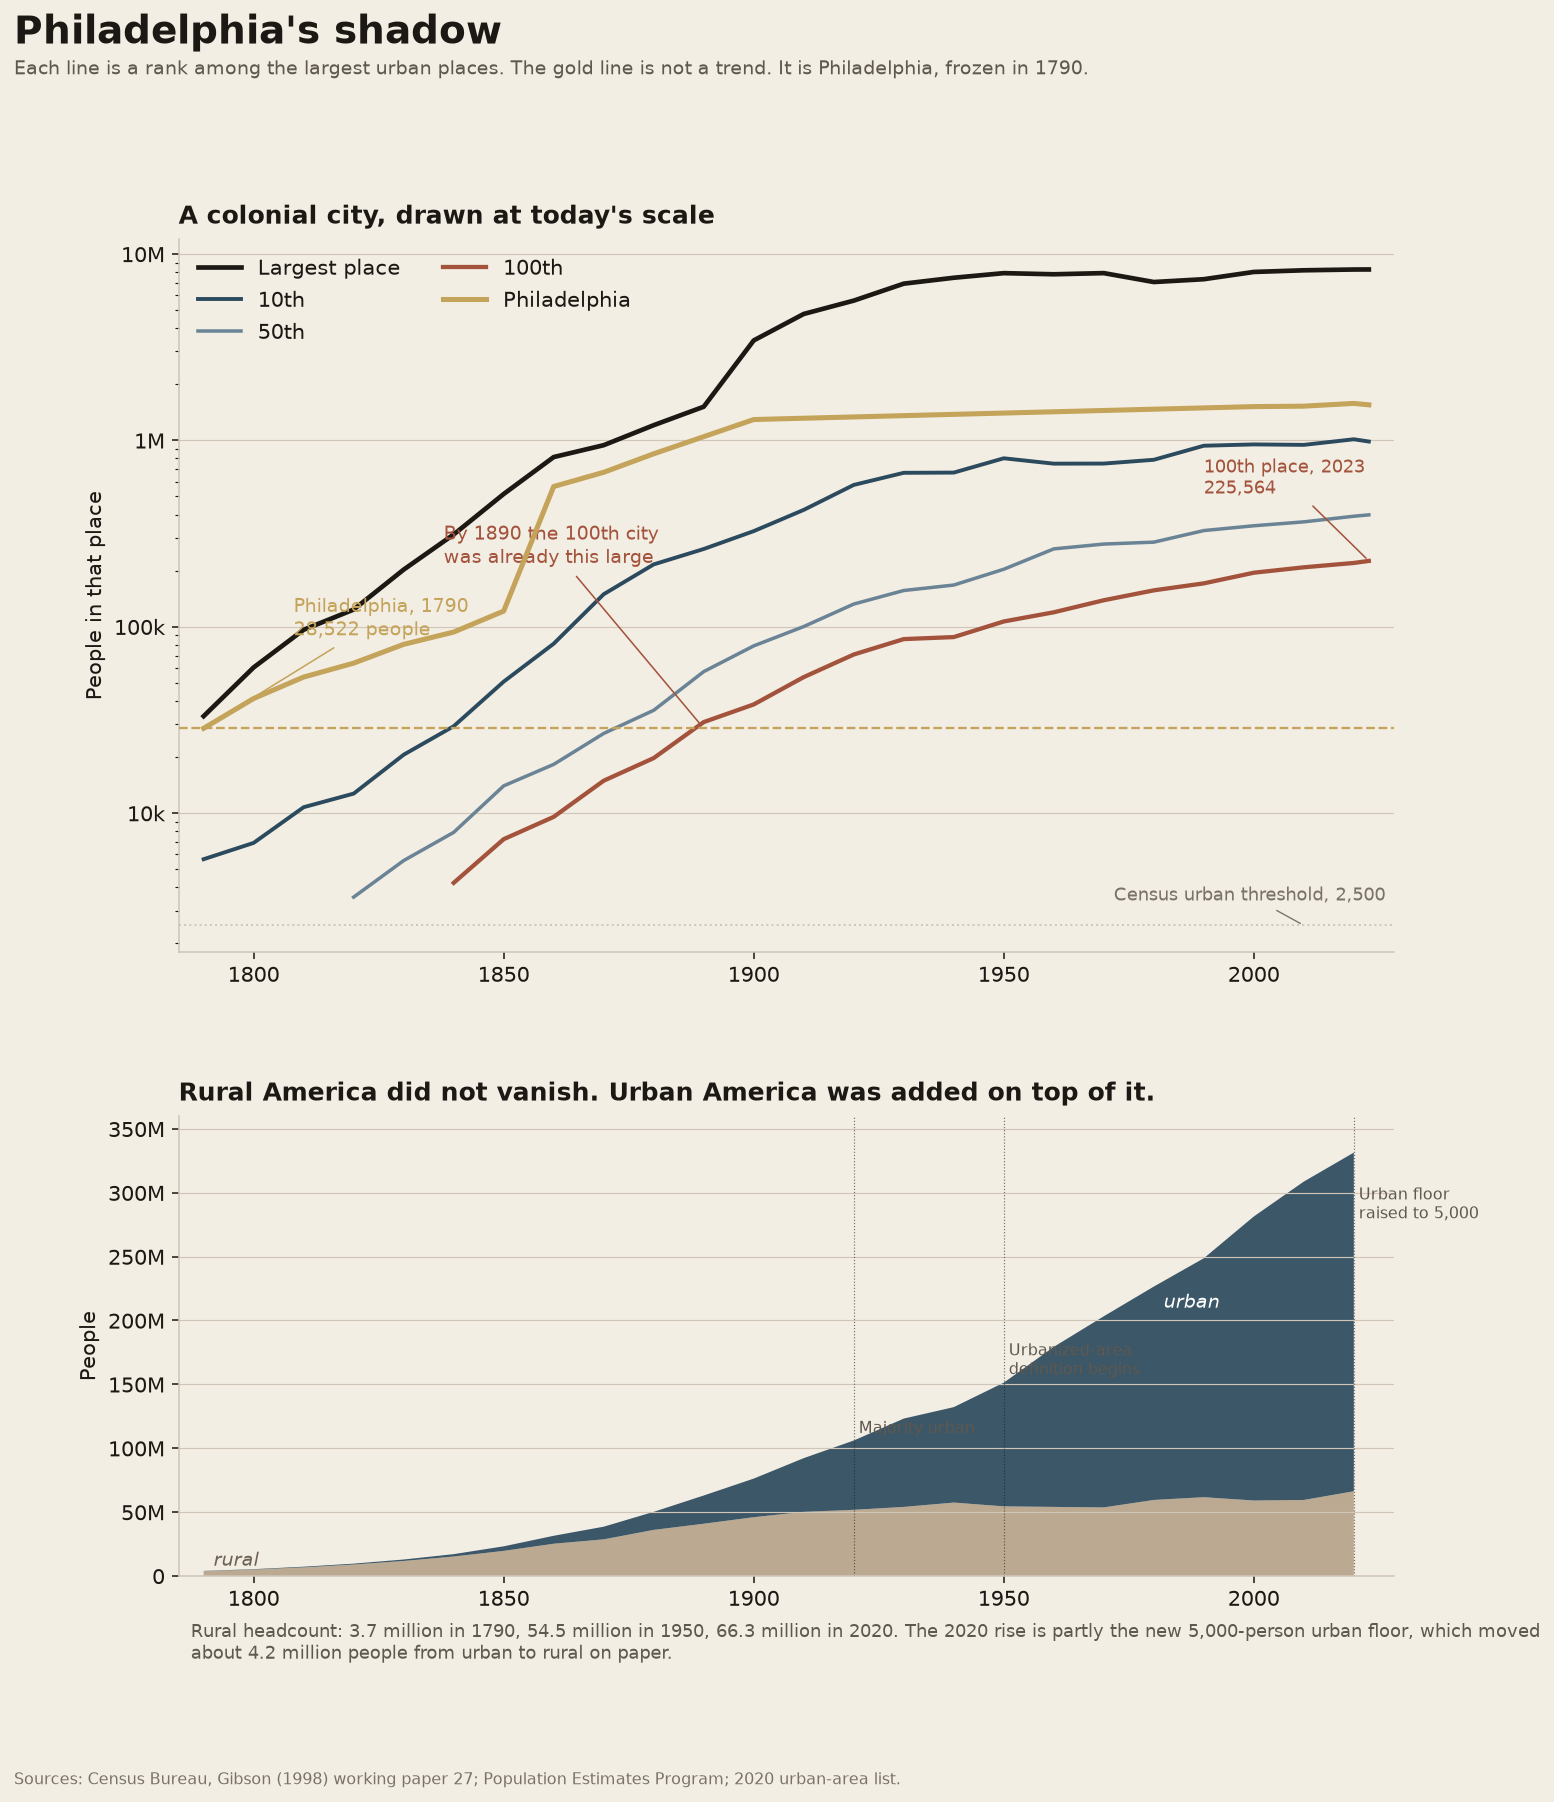

In [9]:
def rank_line(rank: int) -> pd.DataFrame:
    return rank_long[rank_long["rank"] == rank].sort_values("year")


fig = plt.figure(figsize=(11.2, 12.4), dpi=140)
gs = fig.add_gridspec(2, 1, height_ratios=[1.55, 1.0], hspace=0.28)
ax = fig.add_subplot(gs[0])
ax_pop = fig.add_subplot(gs[1])

rank_style = {
    1: dict(color=INK, lw=2.4, label="Largest place"),
    10: dict(color=STEEL, lw=2.0, label="10th"),
    50: dict(color="#6a8496", lw=1.8, label="50th"),
    100: dict(color=MILL, lw=2.2, label="100th"),
}
for rank, style in rank_style.items():
    series = rank_line(rank)
    ax.plot(series["year"], series["population"], **style)

ax.plot(
    philadelphia["year"],
    philadelphia["population"],
    color=GOLD,
    lw=2.6,
    zorder=5,
    label="Philadelphia",
)
ax.axhline(PHILADELPHIA_1790, color=GOLD, lw=1.2, ls="--", zorder=3)
ax.axhline(URBAN_OLD, color=RULE, lw=1.0, ls=":", zorder=2)

ax.set_yscale("log")
ax.set_xlim(1785, 2028)
ax.set_ylim(1_800, 12_000_000)
ax.yaxis.set_major_formatter(FuncFormatter(millions))
ax.set_ylabel("People in that place")
ax.grid(axis="y", color=RULE, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)

# Annotate the measuring stick and the 100th-place crossing.
cross = rank_line(100)
cross = cross[cross["population"] >= PHILADELPHIA_1790].sort_values("year")
cross_year = int(cross.iloc[0]["year"]) if len(cross) else 1890
ax.annotate(
    f"Philadelphia, 1790\n{PHILADELPHIA_1790:,} people",
    xy=(1790, PHILADELPHIA_1790),
    xytext=(1808, 90_000),
    color=GOLD,
    fontsize=10,
    arrowprops=dict(arrowstyle="-", color=GOLD, lw=0.8),
)
ax.annotate(
    f"By {cross_year} the 100th city\nwas already this large",
    xy=(cross_year, PHILADELPHIA_1790),
    xytext=(cross_year - 52, 220_000),
    color=MILL,
    fontsize=10,
    arrowprops=dict(arrowstyle="-", color=MILL, lw=0.8),
)
ax.annotate(
    "Census urban threshold, 2,500",
    xy=(2010, URBAN_OLD),
    xytext=(1972, 3_400),
    color="#7a7268",
    fontsize=9,
    arrowprops=dict(arrowstyle="-", color="#7a7268", lw=0.7),
)
hundred_now = rank_line(100).sort_values("year").iloc[-1]
ax.annotate(
    f"100th place, {int(hundred_now['year'])}\n{int(hundred_now['population']):,}",
    xy=(hundred_now["year"], hundred_now["population"]),
    xytext=(1990, hundred_now["population"] * 2.3),
    color=MILL,
    fontsize=9,
    arrowprops=dict(arrowstyle="-", color=MILL, lw=0.8),
)

leg = ax.legend(frameon=False, loc="upper left", ncol=2)
ax.set_title(
    "A colonial city, drawn at today's scale",
    loc="left",
    pad=8,
    fontweight="bold",
)

# People, not percentages.
ax_pop.stackplot(
    URBAN_RURAL["year"],
    URBAN_RURAL["rural"],
    URBAN_RURAL["urban"],
    colors=[RURAL, STEEL],
    alpha=0.92,
    linewidth=0,
)
for year, label, y in [
    (1920, "Majority urban", 112_000_000),
    (1950, "Urbanized-area\ndefinition begins", 158_000_000),
    (2020, "Urban floor\nraised to 5,000", 280_000_000),
]:
    ax_pop.axvline(year, color=INK, lw=0.6, ls=":", alpha=0.6)
    ax_pop.text(year + 1, y, label, fontsize=8, color="#5e584f")

ax_pop.set_xlim(1785, 2028)
ax_pop.set_ylim(0, 360_000_000)
ax_pop.yaxis.set_major_formatter(FuncFormatter(millions))
ax_pop.set_ylabel("People")
ax_pop.set_xlabel("")
ax_pop.spines[["top", "right"]].set_visible(False)
ax_pop.grid(axis="y", color=RULE, lw=0.6)
ax_pop.set_title(
    "Rural America did not vanish. Urban America was added on top of it.",
    loc="left",
    pad=8,
    fontweight="bold",
)

rural_2020 = int(URBAN_RURAL.loc[URBAN_RURAL.year == 2020, "rural"].iloc[0])
rural_1790 = int(URBAN_RURAL.loc[URBAN_RURAL.year == 1790, "rural"].iloc[0])
rural_1950 = int(URBAN_RURAL.loc[URBAN_RURAL.year == 1950, "rural"].iloc[0])
ax_pop.text(
    1792,
    8_000_000,
    "rural",
    color="#6e6254",
    fontsize=10,
    fontstyle="italic",
)
ax_pop.text(
    1982,
    210_000_000,
    "urban",
    color="white",
    fontsize=10,
    fontstyle="italic",
)
ax_pop.text(
    0.01,
    -0.18,
    (
        f"Rural headcount: {rural_1790/1e6:.1f} million in 1790, {rural_1950/1e6:.1f} million in 1950, "
        f"{rural_2020/1e6:.1f} million in 2020. The 2020 rise is partly the new 5,000-person urban floor, "
        f"which moved about 4.2 million people from urban to rural on paper."
    ),
    transform=ax_pop.transAxes,
    fontsize=9,
    color="#5e584f",
    wrap=True,
)

fig.suptitle("Philadelphia's shadow", x=0.02, ha="left", fontsize=20, fontweight="bold", y=1.01)
fig.text(
    0.02,
    0.975,
    "Each line is a rank among the largest urban places. The gold line is not a trend. It is Philadelphia, frozen in 1790.",
    fontsize=10,
    color="#5e584f",
)
fig.text(
    0.02,
    -0.01,
    "Sources: Census Bureau, Gibson (1998) working paper 27; Population Estimates Program; 2020 urban-area list.",
    fontsize=8,
    color="#7a7268",
)
fig.savefig(HERE / "philadelphia_shadow.png", dpi=160, bbox_inches="tight")
plt.show()


## Taken from the pile

Each square is 200,000 manufacturing jobs in counties, using the 1974 metro line so the geography does not chase the jobs. Brick is nonmetro. Steel is metro. The pale squares are jobs that existed at the 1979 SIC peak and are not in that year's remaining pile.

The pile was not carried from mill towns into cities. From 1979 to 2000, on this fixed map, nonmetro manufacturing held. Metro manufacturing fell. After 2001 both sides shrink, and the missing squares are jobs that left the country, not jobs that moved down the road.

The lower panels keep the same 1974 map. One is jobs. One is people. The dotted line is what "nonmetro" looks like if the rural-urban codes are allowed to update — people who did not move, but whose county was redrawn as metro.


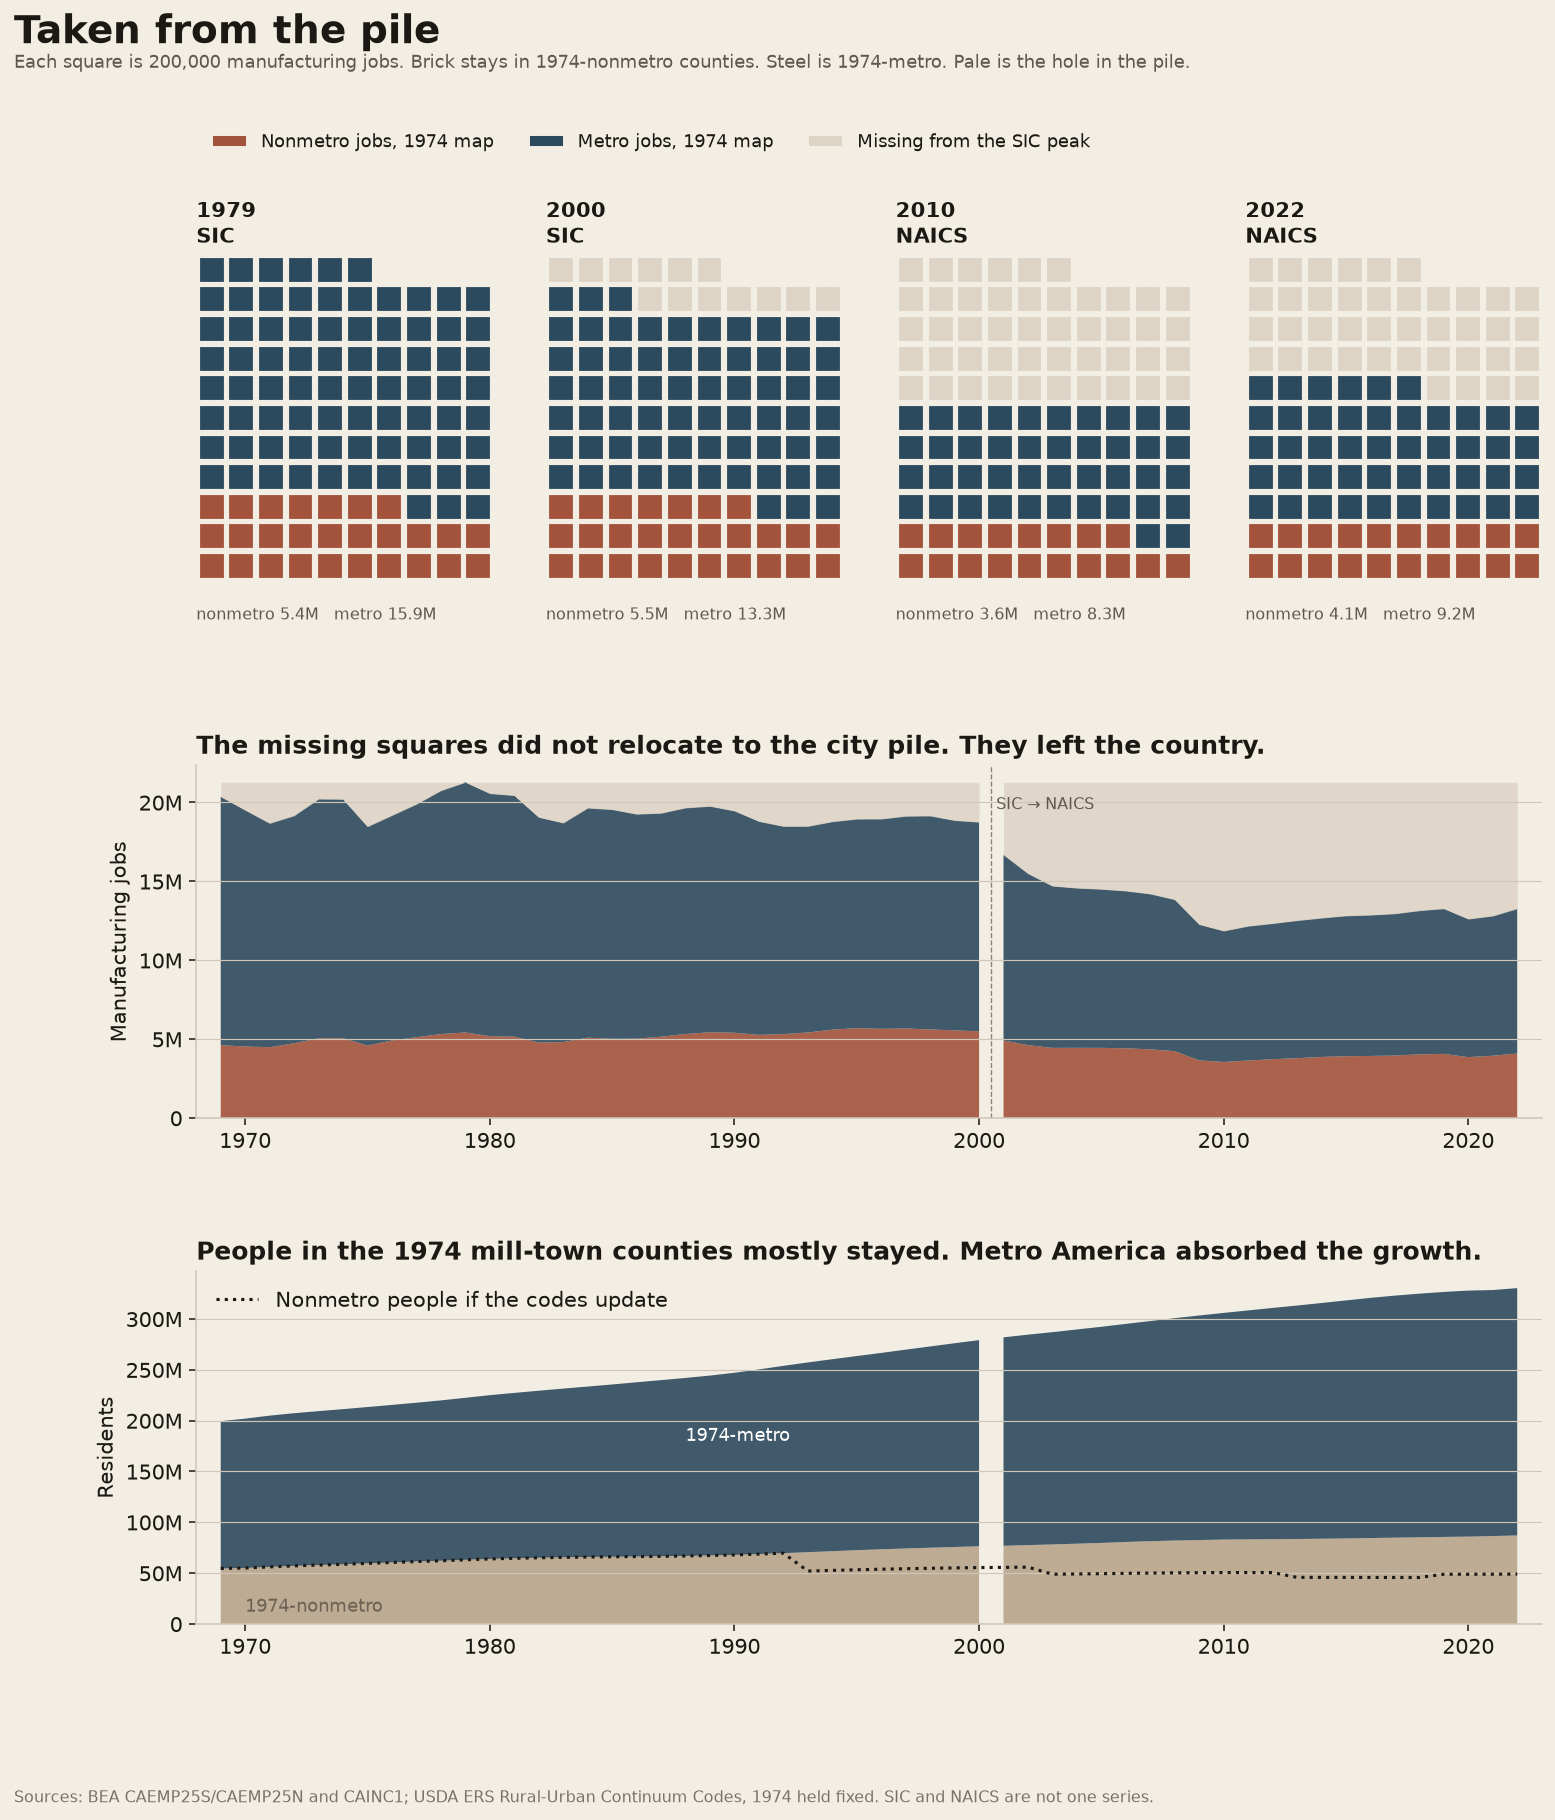

In [10]:
UNIT = 200_000
naics_2010 = naics.loc[naics["year"] == 2010].iloc[0]
WAFFLE_YEARS = [
    ("SIC", int(sic_peak_year), sic_peak),
    ("SIC", 2000, sic_end),
    ("NAICS", 2010, naics_2010),
    ("NAICS", 2022, naics_end),
]
peak_total = float(sic_peak["total_jobs"])


def squares(n_jobs: float) -> int:
    return int(round(float(n_jobs) / UNIT))


def draw_waffle(ax, row, year: int, schema: str, peak: float):
    n_non = squares(row["jobs_nonmetro"])
    n_met = squares(row["jobs_metro"])
    n_gone = max(squares(peak) - n_non - n_met, 0)
    cells = [(MILL, n_non), (STEEL, n_met), (GONE, n_gone)]
    cols = 10
    x = y = 0
    for color, count in cells:
        for _ in range(count):
            ax.add_patch(
                Rectangle(
                    (x + 0.08, y + 0.08),
                    0.84,
                    0.84,
                    facecolor=color,
                    edgecolor=PAPER,
                    lw=0.6,
                    linewidth=0.6,
                )
            )
            x += 1
            if x >= cols:
                x = 0
                y += 1
    nrows = max(y + (1 if x else 0), 1)
    ax.set_xlim(0, cols)
    ax.set_ylim(0, max(nrows, int(np.ceil(squares(peak) / cols))))
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{year}\n{schema}", loc="left", fontsize=11, fontweight="bold", pad=6)
    ax.text(
        0,
        -0.12,
        f"nonmetro {row['jobs_nonmetro']/1e6:.1f}M   metro {row['jobs_metro']/1e6:.1f}M",
        transform=ax.transAxes,
        fontsize=8,
        color="#5e584f",
        clip_on=False,
    )


fig = plt.figure(figsize=(12.4, 13.0), dpi=140)
gs = fig.add_gridspec(
    3, 4, height_ratios=[1.05, 0.95, 0.95], hspace=0.42, wspace=0.18
)

waffle_axes = [fig.add_subplot(gs[0, i]) for i in range(4)]
for ax, (schema, year, row) in zip(waffle_axes, WAFFLE_YEARS):
    draw_waffle(ax, row, year, schema, peak_total)

waffle_axes[0].legend(
    handles=[
        Patch(facecolor=MILL, edgecolor=PAPER, label="Nonmetro jobs, 1974 map"),
        Patch(facecolor=STEEL, edgecolor=PAPER, label="Metro jobs, 1974 map"),
        Patch(facecolor=GONE, edgecolor=PAPER, label="Missing from the SIC peak"),
    ],
    loc="upper left",
    bbox_to_anchor=(0, 1.42),
    frameon=False,
    ncol=3,
    fontsize=9,
)

ax_jobs = fig.add_subplot(gs[1, :])
ax_people = fig.add_subplot(gs[2, :])


def plot_piles(ax, table: pd.DataFrame, value_non: str, value_met: str, peak_value=None):
    for schema, color_edge in [("SIC", INK), ("NAICS", INK)]:
        piece = table[table["schema"] == schema].sort_values("year")
        ax.stackplot(
            piece["year"],
            piece[value_non],
            piece[value_met],
            colors=[MILL, STEEL],
            alpha=0.9,
            linewidth=0,
        )
        if peak_value is not None:
            ax.fill_between(
                piece["year"],
                piece[value_non] + piece[value_met],
                peak_value,
                color=GONE,
                alpha=0.85,
                linewidth=0,
            )


plot_piles(ax_jobs, fixed, "jobs_nonmetro", "jobs_metro", peak_total)
ax_jobs.axvline(2000.5, color=INK, lw=0.7, ls="--", alpha=0.5)
ax_jobs.text(2000.7, peak_total * 0.92, "SIC → NAICS", fontsize=8, color="#5e584f")
ax_jobs.set_ylabel("Manufacturing jobs")
ax_jobs.yaxis.set_major_formatter(FuncFormatter(millions))
ax_jobs.set_xlim(1968, 2023)
ax_jobs.set_ylim(0, peak_total * 1.05)
ax_jobs.spines[["top", "right"]].set_visible(False)
ax_jobs.grid(axis="y", color=RULE, lw=0.6)
ax_jobs.set_title(
    "The missing squares did not relocate to the city pile. They left the country.",
    loc="left",
    fontweight="bold",
)

# People on the same 1974 map, plus contemporaneous nonmetro as a dotted line.
for schema in ("SIC", "NAICS"):
    piece = fixed[fixed["schema"] == schema].sort_values("year")
    ax_people.stackplot(
        piece["year"],
        piece["population_nonmetro"],
        piece["population_metro"],
        colors=[RURAL, STEEL],
        alpha=0.9,
        linewidth=0,
    )
moving_sorted = moving.sort_values("year")
ax_people.plot(
    moving_sorted["year"],
    moving_sorted["population_nonmetro"],
    color=INK,
    lw=1.6,
    ls=":",
    label="Nonmetro people if the codes update",
)
ax_people.set_ylabel("Residents")
ax_people.yaxis.set_major_formatter(FuncFormatter(millions))
ax_people.set_xlim(1968, 2023)
ax_people.spines[["top", "right"]].set_visible(False)
ax_people.grid(axis="y", color=RULE, lw=0.6)
ax_people.set_title(
    "People in the 1974 mill-town counties mostly stayed. Metro America absorbed the growth.",
    loc="left",
    fontweight="bold",
)
ax_people.legend(frameon=False, loc="upper left")
ax_people.text(1970, 12_000_000, "1974-nonmetro", color="#6e6254", fontsize=9)
ax_people.text(1988, 180_000_000, "1974-metro", color="white", fontsize=9)

fig.suptitle("Taken from the pile", x=0.02, ha="left", fontsize=20, fontweight="bold", y=0.995)
fig.text(
    0.02,
    0.965,
    "Each square is 200,000 manufacturing jobs. Brick stays in 1974-nonmetro counties. Steel is 1974-metro. Pale is the hole in the pile.",
    fontsize=9,
    color="#5e584f",
)
fig.text(
    0.02,
    0.012,
    "Sources: BEA CAEMP25S/CAEMP25N and CAINC1; USDA ERS Rural-Urban Continuum Codes, 1974 held fixed. SIC and NAICS are not one series.",
    fontsize=8,
    color="#7a7268",
)
fig.savefig(HERE / "taken_from_the_pile.png", dpi=160, bbox_inches="tight")
plt.show()


## What the cleaned files say


In [11]:
phl_now = philadelphia.sort_values("year").iloc[-1]
hundred_1890 = rank_long[(rank_long["year"] == 1890) & (rank_long["rank"] == 100)]
hundred_2020 = rank_long[(rank_long["year"] == 2020) & (rank_long["rank"] == 100)]
urban_1920 = URBAN_RURAL.loc[URBAN_RURAL.year == 1920].iloc[0]
jobs_left_sic = sic_peak["jobs_nonmetro"] - sic_end["jobs_nonmetro"]
jobs_left_naics = naics_start["jobs_nonmetro"] - naics_end["jobs_nonmetro"]
jobs_gone_sic = sic_peak["total_jobs"] - sic_end["total_jobs"]
jobs_to_metro_sic = sic_end["jobs_metro"] - sic_peak["jobs_metro"]

print("City-size stick")
print(
    f"  Philadelphia 1790: {PHILADELPHIA_1790:,}. "
    f"Philadelphia {int(phl_now.year)}: {int(phl_now.population):,}."
)
if len(hundred_1890):
    print(f"  100th place in 1890: {int(hundred_1890.iloc[0].population):,}")
if len(hundred_2020):
    print(f"  100th place in 2020: {int(hundred_2020.iloc[0].population):,}")
print(
    f"  2020 urban areas smaller than Philadelphia 1790: {n_smaller_phl:,}. "
    f"{pop_in_larger_phl/1e6:.1f} million people live in urban areas at least that large."
)

print("\nHeadcounts, not rates")
print(
    f"  Rural people: {rural_1790/1e6:.1f}M (1790), {rural_1950/1e6:.1f}M (1950), "
    f"{rural_2020/1e6:.1f}M (2020, new definition)."
)
print(
    f"  First census with an urban majority: 1920, "
    f"{urban_1920.urban/1e6:.1f}M urban of {urban_1920.total/1e6:.1f}M ({urban_1920.pct_urban:.1f}%)."
)

print("\nThe pile, 1974 map")
print(
    f"  Nonmetro manufacturing jobs changed by { -jobs_left_sic/1e6:.2f}M from {sic_peak_year} to 2000 (SIC), "
    f"then { -jobs_left_naics/1e6:.2f}M from 2001 to 2022 (NAICS)."
)
print(
    f"  National manufacturing jobs changed by {-jobs_gone_sic/1e6:.2f}M from {sic_peak_year} to 2000. "
    f"Metro manufacturing changed by {jobs_to_metro_sic/1e6:.2f}M in that window."
)
print(
    f"  People in 1974-nonmetro counties: "
    f"{sic_start['population_nonmetro']/1e6:.1f}M (1969) → "
    f"{naics_end['population_nonmetro']/1e6:.1f}M (2022)."
)
print(
    f"  People in 1974-metro counties: "
    f"{sic_start['population_metro']/1e6:.1f}M → {naics_end['population_metro']/1e6:.1f}M."
)

idx_jobs = 100 * naics_end["jobs_nonmetro"] / sic_start["jobs_nonmetro"]
idx_people = 100 * naics_end["population_nonmetro"] / sic_start["population_nonmetro"]
print(
    f"  Index, 1969=100, 1974-nonmetro counties, 2022: "
    f"manufacturing jobs {idx_jobs:.0f}, residents {idx_people:.0f}. "
    f"The two industrial classifications make the job index a sketch, not a single ratio."
)
print("Wrote philadelphia_shadow.png and taken_from_the_pile.png")


City-size stick
  Philadelphia 1790: 28,522. Philadelphia 2023: 1,550,542.
  100th place in 1890: 30,801
  100th place in 2020: 219,945
  2020 urban areas smaller than Philadelphia 1790: 1,923. 244.6 million people live in urban areas at least that large.

Headcounts, not rates
  Rural people: 3.7M (1790), 54.5M (1950), 66.3M (2020, new definition).
  First census with an urban majority: 1920, 54.3M urban of 106.0M (51.2%).

The pile, 1974 map
  Nonmetro manufacturing jobs changed by 0.07M from 1979 to 2000 (SIC), then -0.83M from 2001 to 2022 (NAICS).
  National manufacturing jobs changed by -2.53M from 1979 to 2000. Metro manufacturing changed by -2.60M in that window.
  People in 1974-nonmetro counties: 54.5M (1969) → 87.0M (2022).
  People in 1974-metro counties: 144.9M → 243.3M.
  Index, 1969=100, 1974-nonmetro counties, 2022: manufacturing jobs 89, residents 160. The two industrial classifications make the job index a sketch, not a single ratio.
Wrote philadelphia_shadow.png and 

## Limits

Gibson's ranks through 1990 are urban places as the Census then defined them. The 2000–2023 ranks are incorporated places in the Population Estimates Program. A large CDP can sit in one list and not the other. Annexation also moves people into a city without anyone changing house.

The national urban/rural series changes definition in 1950 and again in 2020. The 2020 rural increase is partly 4.2 million people whose places fell below the new 5,000-person floor. A rising rural count in that year is not a migration wave.

BEA manufacturing jobs include proprietors and are suppressed in some counties. Nonmetro sums are therefore low relative to metro sums. SIC manufacturing in 2000 is not NAICS manufacturing in 2001. The waffle's pale squares after 2000 should be read as two separate losses, not one accounting identity.

The 1974 Rural-Urban Continuum is a county line, not a town line. A mill town inside a county that OMB already called metro in 1974 is on the steel side of the pile. Independent cities in Virginia are sometimes combined in BEA and unmatched to ERS, so they drop out of the join.

FRED `MANEMP` is payroll employment, national, and not used in the piles. It is only a check that the BEA peak sits in the same era as the CES peak, 1979.

None of this is a civic-life survey. It is the geographic half of the story Putnam was walking through: the mill, the town, and the city, counted as jobs and as people.
